# AI-Driven Server Session Anomaly Detection
**Objective:** Automatically identify compromised employee accounts and automated scraping behavior from server access logs using unsupervised machine learning (`Isolation Forest`).

### Business Context
Security teams rarely have pre-labeled examples of every new attack pattern. Rather than relying solely on static rules, this workflow establishes a baseline of normal employee activity (`failed_logins`, `mb_transferred`, and `requests_per_min`) and flags statistical outliers for immediate Tier-1 triage.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

rng = np.random.default_rng(42)

normal_data = pd.DataFrame({
    "user_id": [f"emp_{i:03d}" for i in range(200)],
    "failed_logins": rng.poisson(lam=0.3, size=200),
    "mb_transferred": rng.normal(loc=45, scale=12, size=200).clip(5, 100),
    "requests_per_min": rng.normal(loc=18, scale=5, size=200).clip(2, 40),
})

anomalies = pd.DataFrame({
    "user_id": ["emp_042", "emp_108", "emp_155", "emp_179", "emp_191"],
    "failed_logins": [14, 1, 9, 0, 18],  # Brute-force spikes
    "mb_transferred": [52, 480, 60, 610, 40],  # Data exfiltration spikes
    "requests_per_min": [95, 88, 72, 110, 120],  # Automated bot/scraping rate
})

df = (
    pd.concat([normal_data, anomalies], ignore_index=True)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)
df.head()

,user_id,failed_logins,mb_transferred,requests_per_min
0,emp_015,0,50.658462,12.413079
1,emp_009,0,43.394124,19.665352
2,emp_100,0,62.711389,21.313330
3,emp_132,0,60.714608,12.218262
4,emp_068,0,36.630914,14.558139


### Unsupervised Anomaly Scoring
We fit an **Isolation Forest** model with `contamination=0.03` (expecting roughly 3% of sessions to be anomalous). The algorithm isolates outliers by randomly partitioning feature values—suspicious sessions require far fewer splits to isolate and receive an `anomaly_flag` of **`-1`**.

In [3]:
features = ["failed_logins", "mb_transferred", "requests_per_min"]
model = IsolationForest(contamination=0.03, random_state=42)

# Predict outputs -1 for anomalies and 1 for normal sessions
df["anomaly_flag"] = model.fit_predict(df[features])

suspicious = df[df["anomaly_flag"] == -1]
print(f"Flagged {len(suspicious)} suspicious sessions:")
suspicious

Flagged 7 suspicious sessions:


,user_id,failed_logins,mb_transferred,requests_per_min,anomaly_flag
33,emp_155,9,60.000000,72.000000,-1
82,emp_042,14,52.000000,95.000000,-1
121,emp_179,0,610.000000,110.000000,-1
140,emp_003,2,65.744372,27.755063,-1
172,emp_108,1,480.000000,88.000000,-1
196,emp_191,18,40.000000,120.000000,-1
201,emp_014,2,38.336073,7.635083,-1


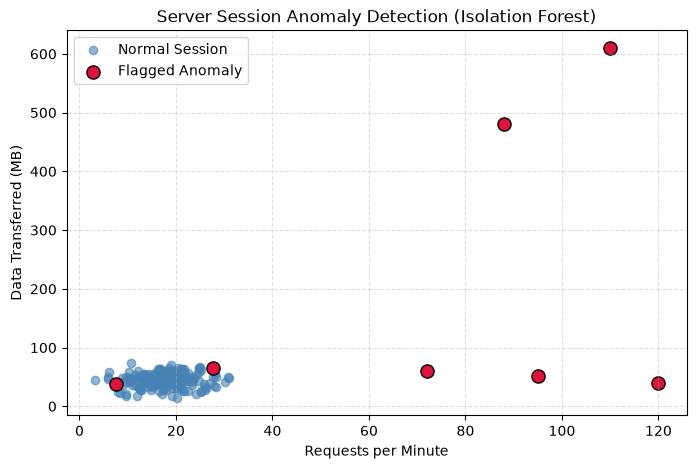

<Figure size 640x480 with 0 Axes>

In [4]:
normal = df[df["anomaly_flag"] == 1]

plt.figure(figsize=(8, 5))
plt.scatter(
    normal["requests_per_min"],
    normal["mb_transferred"],
    c="steelblue",
    alpha=0.6,
    label="Normal Session",
)
plt.scatter(
    suspicious["requests_per_min"],
    suspicious["mb_transferred"],
    c="crimson",
    s=90,
    edgecolors="black",
    label="Flagged Anomaly",
)

plt.title("Server Session Anomaly Detection (Isolation Forest)")
plt.xlabel("Requests per Minute")
plt.ylabel("Data Transferred (MB)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
import os

os.makedirs("assets", exist_ok=True)
plt.savefig("assets/anomaly_scatter.png", dpi=150, bbox_inches="tight")
plt.show()
plt.savefig("assets/anomaly_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

### Investigation Takeaways & Recommended Actions
* **Brute-Force Indicators (`failed_logins` spikes):** Accounts showing high failed login counts paired with high request rates should have active sessions revoked and MFA enforced immediately.
* **Data Exfiltration Indicators (`mb_transferred` spikes):** High outbound data volume with zero failed logins points to potential insider misuse or stolen session tokens—escalate to firewall egress log review.